In [55]:
import h5py
import pylab as plt
import numpy as np
from matplotlib.dates import num2date
from datetime import datetime
import pytz
import matplotlib.ticker as ticker

# Load Samples Data

In [39]:
hdf_samples = h5py.File('../data/validation/unsignedflux_samples.h5')
print(hdf_samples.keys())
#lat_extent_samples = hdf_samples['lat_extent'][:].squeeze()
unsigned_flux_samples = hdf_samples['unsigned_flux'][:].squeeze()
times_d2n = hdf_samples['times_d2n'][:]
hdf_samples.close()

<KeysViewHDF5 ['contexts', 'rs', 'times_d2n', 'unsigned_flux']>


In [40]:
unsigned_flux_samples.shape

(835, 4)

In [41]:
times_samples = np.array(num2date(times_d2n))

In [42]:
unsigned_flux_samples

array([[136995.77721072,   2514.10266459,   1320.95423613,
           986.26767724],
       [115904.42246226,   2037.3917908 ,    838.43739934,
           519.31300458],
       [121846.23774326,   2030.2155808 ,   1025.29029578,
           724.29880342],
       ...,
       [232800.47526377,   3924.50466677,   1595.95152025,
           921.90229178],
       [181728.35816004,   4031.83785119,   1773.58528701,
          1053.12801911],
       [141559.4042349 ,   3515.94203283,   1461.77149248,
           878.86655869]], shape=(835, 4))

# Load Training Data

In [43]:
hdf_testdata = h5py.File('../data/validation/unsignedflux_testdata.h5')
unsigned_flux_testdata = hdf_testdata['unsigned_flux'][:].squeeze()
hdf_testdata.close()

In [44]:
unsigned_flux_testdata.shape

(835, 4)

In [45]:
unsigned_flux_testdata

array([[157078.13428143,   2224.45728304,   1313.85903738,
          1007.12179276],
       [124517.81193924,   2002.39891689,   1211.97437464,
           953.07704312],
       [174747.41673807,   2284.20190364,   1234.33329262,
           906.05566932],
       ...,
       [118091.5118146 ,   2169.16437101,   1431.27044653,
          1151.4307471 ],
       [118091.5118146 ,   2169.16437101,   1431.27044653,
          1151.4307471 ],
       [118091.5118146 ,   2169.16437101,   1431.27044653,
          1151.4307471 ]], shape=(835, 4))

# Plot Experiment

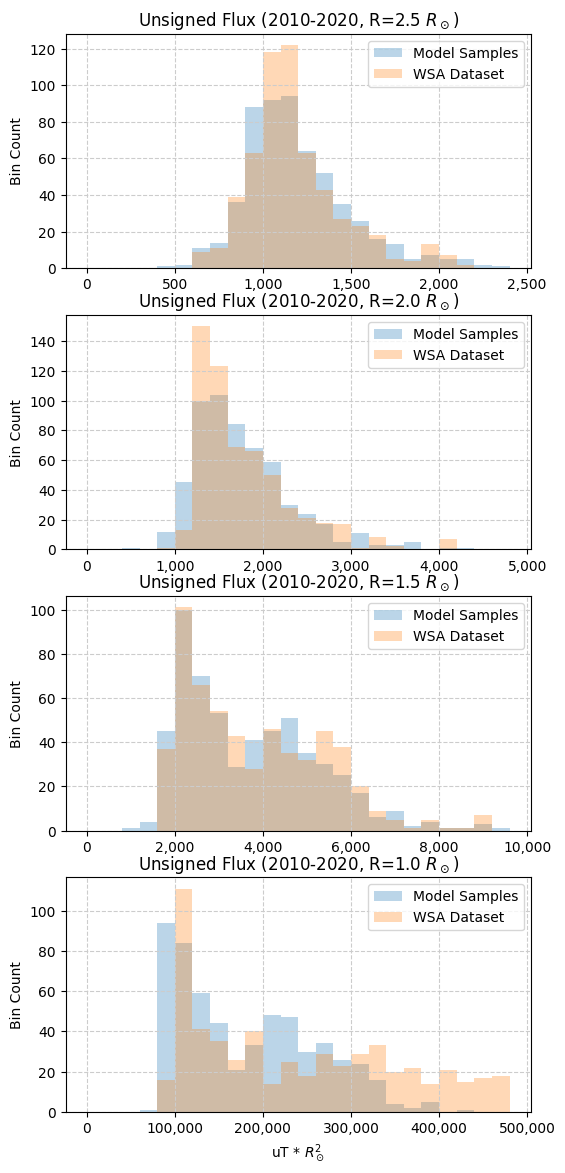

In [62]:
#bins = np.arange(0, 50000, 1000)

bins = [
    np.arange(0, 500_000, 20000),  
    np.arange(0, 500_000, 20000) / 50, 
    np.arange(0, 500_000, 20000) / 100, 
    np.arange(0, 500_000, 20000) / 200, 

]
radii = [1.0, 1.5, 2.0, 2.5]

cutoff = datetime(2021, 1, 1).replace(tzinfo=pytz.utc)  
mask = times_samples < cutoff

fig, axes = plt.subplots(4, 1, figsize=(6, 14))

for i in range(4):
    ax = axes[len(axes) - 1 - i]
        
    ax.set_title(rf'Unsigned Flux (2010-2020, R={radii[i]} $R_\odot$)')
    ax.hist(unsigned_flux_samples[mask, i], label='Model Samples', bins=bins[i], alpha=0.3)
    ax.hist(unsigned_flux_testdata[mask, i], bins=bins[i],  label='WSA Dataset', alpha=0.3)
    
    ax.legend()
    ax.set_ylabel('Bin Count')
    if i == 0: ax.set_xlabel(r'uT * $R_\odot^2$')
    ax.grid(linestyle='dashed', color='#ccc')
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

fig.savefig('../plots/paper/unsignedflux.png', dpi=300)

In [47]:
for i in range(4):
    print(np.mean(unsigned_flux_testdata[mask, i])  /  np.mean(unsigned_flux_samples[mask, i]) )

1.3237697344434793
1.0306209798625794
1.0017014344258774
0.9937320084551529


In [48]:
 1/ (np.pi * 4 * np.sqrt(2))

np.float64(0.05626976975981913)

In [61]:

for i in range(4):
    print(f"Layer {i}")
    print("="*40)
    print('Samples')
    print('---------')
    print('Mean', np.mean(unsigned_flux_samples[mask,i]))
    print('STD', np.std(unsigned_flux_samples[mask, i]))
    print()
    print('WSA Dataset')
    print('---------')
    print('Mean', np.mean(unsigned_flux_testdata[mask, i]))
    print('STD', np.std(unsigned_flux_testdata[mask, i]))
    print()

Layer 0
Samples
---------
Mean 183106.31622924548
STD 78722.41950432179

WSA Dataset
---------
Mean 242390.59960971202
STD 117910.72987124645

Layer 1
Samples
---------
Mean 3710.4658766301854
STD 1569.768831847074

WSA Dataset
---------
Mean 3824.083977519266
STD 1583.0538284895642

Layer 2
Samples
---------
Mean 1776.592837846219
STD 571.0710583106697

WSA Dataset
---------
Mean 1779.6155940612978
STD 549.1916843128153

Layer 3
Samples
---------
Mean 1206.9730039513252
STD 329.08509161143655

WSA Dataset
---------
Mean 1199.4077073676995
STD 304.1383602574198

